# Design an Achromatic Doublet — nominal lateral-color entry

[Optiland competition](https://www.optiland.org/competitions), ID `f25db72f-a90b-4c41-af3c-9dcd85fb2090`. This is a self-created spherical N-BK7/F2 doublet from thin-achromat power seeds, not a private lens prescription.

**This is a local, explicitly defined evaluation, not an official server score or a global-optimality claim.** The linked public template was unavailable. The public rules do not define chief versus centroid lateral color or Gaussian versus real d-line focus. This entry scores **chief-ray F-C color at 3° on the fixed 588 nm Gaussian plane**, reports centroid color separately, and never focuses F/C independently. All three stated wavelengths are used exactly: **486/588/656 nm**, with primary **588 nm**; these are the rules' rounded values, not substituted Fraunhofer decimals.

The selected nominal design has **29.999860 mm and 19.464452 mm center thicknesses**, with diameters **13.025904 mm and 13.787629 mm**. The declared local CT search bounds were 2.05–30 mm, so the crown is near the upper bound. The competition specifies no CT maximum. A separate CT≤14 mm branch is included below. No practical fabrication, tolerance, assembly or diffraction-limited performance is claimed.

An important unscored limitation is retained visibly: the F-C **axial Gaussian focus separation is 0.4644295 mm**. Small chief-ray lateral color does not imply full broadband axial achromatization. The scored RMS values are **588 nm only**, not polychromatic.


In [1]:
import importlib.metadata, importlib.util, subprocess, sys

# Pin the exact public source revision used for the independent Optiland check.
revision = 'a9e544a2e058f1c1b64606e9ce90e6dc103efee1'
installed = importlib.metadata.version('optiland') if importlib.util.find_spec('optiland') else ''
if 'ga9e544a2' not in installed:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                           'git+https://github.com/optiland/optiland.git@' + revision])

import json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optiland.backend as be
from optiland.materials import Material, IdealMaterial
from optiland.materials.material_spec import MatchPolicy
from optiland.optic import Optic
from optiland.physical_apertures import RadialAperture
from optiland.rays import RealRays
be.set_backend('numpy')
print('Optiland:', importlib.metadata.version('optiland'))
print('NumPy:', np.__version__)


Optiland: 0.6.2.post234+ga9e544a2
NumPy: 2.3.5


## Search stages and source-algorithm reproduction

Synthetic cemented and air-spaced starts were locally conditioned using **SciPy bounded `least_squares` with standalone-optics real-ray residuals**. Full pupil circumference and all three colors were checked before accepting a design. This SciPy refinement is explicitly separate from the repository's own candidate search.

The next cell runs the **unchanged original standalone-optics** generator and wavefront-ranked CPU/CUDA coarse screen: 15 candidates, curvature surfaces 1/3/4, actual change bounds **±5×10⁻⁷ mm⁻¹**, coarse 6×24 pupil quadrature, and CPU 20×64 replay of eight finalists plus the baseline. It ranks worst/mean RMS wavefront and spot diagnostics. This narrow micro-curvature validation stage is **not a global optimizer**. Its candidates share the fixed starting image plane. The chosen candidate subsequently gets its new single 588 nm Gaussian plane and one separate bounded SciPy refinement of the contest metric. The final refinement reached its evaluation budget; no stationarity or global optimum is asserted.

Pinned public Python sources are SHA-256 verified. A CUDA rerun is optional when a CUDA/CuPy environment is available; CPU reproduction does not require it. Initial GPU compilation is reported separately from warmed coarse evaluation.


In [2]:
source_payload=json.loads(r'''{
  "commit": "d130999165abc8ccc1865c4ef145cd6bda191a4d",
  "files": {
    "scripts/ai_zemax/__init__.py": "bded78d0cee5a6d576ad22817032e8d5eb32903f0683633c5e9b117c3015d7d5",
    "scripts/ai_zemax/standalone.py": "84e8b3f11775dc8ce133067cc2f94938493ffae852edcc155cfb4408a70d8fac",
    "scripts/ai_zemax/standalone_aberrations.py": "ee2b7dd9f0fe528448e557292e2fb9179c84bcdbfcf0ed674f8914b11a5e5f52",
    "scripts/ai_zemax/standalone_analysis.py": "ec5dfabc5ee6a1670e638b4bbf2e99479e013263c6423af73557b8906916224a",
    "scripts/ai_zemax/standalone_candidate_generation.py": "fa3264316a47c0cb3a54d4a6812193e86c904c16e56b38eb2f54538dd83a3335",
    "scripts/ai_zemax/standalone_cli.py": "7aa8ee9f4796137389bd3fbc7b89715ca25cf9e2f27b7d07b254f0d05a67cc1e",
    "scripts/ai_zemax/standalone_coupled_group_search.py": "8399516b597dd6ce991ba8775e6d15560b03ae73df5117f555b7e3a6a31a0764",
    "scripts/ai_zemax/standalone_demo.py": "73b4b7cbccebc7404c41e61a12f5a22440f4821c3c2c1a46ceeffe7e8ba10cdf",
    "scripts/ai_zemax/standalone_gpu_screen.py": "60d227a0f23688288e8c368880f12e5242864519fe1487cd85f3883f59436676",
    "scripts/ai_zemax/standalone_gpu_trace.py": "3aeb0d8b234635a24fa15fae74fa90e70ffb04a2353ea673368887f1ddb3f926",
    "scripts/ai_zemax/standalone_group_search.py": "94d3b15d2f06dd0e078a56241e61c7054577d6ed58c74be816ca3fb53a19efbd",
    "scripts/ai_zemax/standalone_manufacturing.py": "97ebf815911b88bd5b0d7de99390c8ee41b8b2972aaac122b9d5ee69063a5113",
    "scripts/ai_zemax/standalone_model.py": "26c82fe38588006b28d648961aa7dc825929c917fcee5065fa86ee890a44e3fb",
    "scripts/ai_zemax/standalone_mtf.py": "4212682c206e8acb31ae9ae12d5866d1b1e70d115672056367a9f5d0ce88fce9",
    "scripts/ai_zemax/standalone_mtf_geometric.py": "1ded7cc0fd3e75a7a3fbcd06d2bee7496403fa90eaa7bc6fa44bb2489b36b28b",
    "scripts/ai_zemax/standalone_mtf_workflow.py": "9c5b3f6ce43c70fe1ce8833f9062248c045bf2cf44d4e7f3fa0d9def402c20d4",
    "scripts/ai_zemax/standalone_optimization_cli.py": "9b8a54579e0e315941bbc905cc6adeb1631e4536f3616a01040357b8d3b1bf20",
    "scripts/ai_zemax/standalone_parallel_screen.py": "13fcb1e8e9d6b44b4d5ff510e9dc51f29c00e6eeef0423d0f0c064b898c7e827",
    "scripts/ai_zemax/standalone_plots.py": "d57fba66dc57b27be954e3b7f153cb13a6a279812851f1d2c81f1fee8d5e7160",
    "scripts/ai_zemax/standalone_seed_realize.py": "f2c6330527eff290dd5543719e753e56a9864549fbc9ba06d1c9fea41fce9074",
    "scripts/ai_zemax/standalone_seed_search.py": "c5d1fe334277fe82635525d9acf9a9953ddd4af33bae4f7bcc0da00d9ed9c577",
    "scripts/ai_zemax/standalone_spot.py": "d0d8171b8acf61639585a61896ed7e061ac15f4726af0434d3fe488a806c82d0",
    "scripts/ai_zemax/standalone_system.py": "54ef9eb7963e7153976b0dc6cd0701092ca44038ea8b7f04eb9b6c645f15b0bd"
  },
  "model": {
    "vertices_mm": [
      0.0,
      29.999802725045907,
      30.107373514380285,
      49.16535590867535,
      129.43589577585553
    ],
    "surface_rows": [
      {
        "curvature_mm_inv": 0.014503314421213189,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 6.51530309071724,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": -0.04612155199497219,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 6.51530309071724,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": -0.04538057608658288,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 6.889324701822314,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": -0.012225706344772038,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 6.889324701822314,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      },
      {
        "curvature_mm_inv": 0.0,
        "conic": 0.0,
        "even_coefficients": [],
        "aperture_radius_mm": 5.412414154532496,
        "surface_type": "STANDARD",
        "focal_length_mm": null
      }
    ],
    "wavelengths_um": [
      0.486,
      0.588,
      0.656
    ],
    "wavelength_weights": [
      1.0,
      1.0,
      1.0
    ],
    "indices_by_wave": [
      [
        1.0,
        1.522385894349391,
        1.0,
        1.6321030067298463,
        1.0,
        1.0
      ],
      [
        1.0,
        1.5167817367777037,
        1.0,
        1.6200022808636685,
        1.0,
        1.0
      ],
      [
        1.0,
        1.5143308473500767,
        1.0,
        1.6150484339456406,
        1.0,
        1.0
      ]
    ],
    "fields": [
      [
        0.0,
        0.0
      ],
      [
        0.0,
        1.5
      ],
      [
        0.0,
        3.0
      ]
    ],
    "field_weights": [
      1.0,
      1.0,
      1.0
    ],
    "field_unit": "deg",
    "stop_surface": 1,
    "primary_wave": 1,
    "object_at_infinity": true,
    "field_type": "angle",
    "aperture_type": "enpd",
    "aperture_value": 12.5,
    "ray_aiming": "off",
    "gaussian_apodization": 0.0
  },
  "config": {
    "candidate_count": 15,
    "random_seed": 23,
    "curvature_variables": [
      {
        "surface": 1,
        "min_delta_mm_inv": -5e-07,
        "max_delta_mm_inv": 5e-07
      },
      {
        "surface": 3,
        "min_delta_mm_inv": -5e-07,
        "max_delta_mm_inv": 5e-07
      },
      {
        "surface": 4,
        "min_delta_mm_inv": -5e-07,
        "max_delta_mm_inv": 5e-07
      }
    ],
    "screening": {
      "manufacturing_policy": {
        "schema_version": 1,
        "policy_id": "doublet-contest-nominal-solids",
        "all_spherical": true,
        "sources": [
          "https://www.optiland.org/competitions"
        ],
        "notes": [
          "Additional nominal geometry guard, not manufacturing/tolerance acceptance.",
          "Full-wave/rim transmission is audited independently before final acceptance."
        ],
        "radial_samples": 1025,
        "surfaces": {
          "1": {
            "clear_radius_mm": 6.51530309071724,
            "mechanical_radius_mm": 6.51530309071724
          },
          "2": {
            "clear_radius_mm": 6.51530309071724,
            "mechanical_radius_mm": 6.51530309071724
          },
          "3": {
            "clear_radius_mm": 6.889324701822314,
            "mechanical_radius_mm": 6.889324701822314
          },
          "4": {
            "clear_radius_mm": 6.889324701822314,
            "mechanical_radius_mm": 6.889324701822314
          },
          "5": {
            "clear_radius_mm": 5.412414154532496,
            "mechanical_radius_mm": 5.412414154532496
          }
        },
        "lenses": [
          {
            "front_surface": 1,
            "rear_surface": 2
          },
          {
            "front_surface": 3,
            "rear_surface": 4
          }
        ],
        "defaults": {
          "minimum_center_thickness_mm": 2.0,
          "minimum_radial_thickness_mm": 1.0,
          "minimum_air_gap_mm": 0.0,
          "minimum_rim_gap_mm": 0.0,
          "minimum_clear_to_mechanical_radial_margin_mm": 0.0
        }
      }
    }
  }
}''')
import hashlib, os, tempfile, urllib.request
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

with tempfile.TemporaryDirectory(prefix='public-optics-screen-') as directory:
    work=Path(directory);scripts=work/'repo'/'scripts'
    def fetch_file(item):
        relative,expected=item
        url='https://raw.githubusercontent.com/wufansaber/standalone-optics/'+source_payload['commit']+'/'+relative
        data=urllib.request.urlopen(url,timeout=45).read()
        if hashlib.sha256(data).hexdigest()!=expected:raise RuntimeError('Source hash mismatch: '+relative)
        target=work/'repo'/relative;target.parent.mkdir(parents=True,exist_ok=True);target.write_bytes(data)
    with ThreadPoolExecutor(max_workers=6) as executor:list(executor.map(fetch_file,source_payload['files'].items()))
    (work/'model.json').write_text(json.dumps(source_payload['model']),encoding='utf8')
    (work/'config.json').write_text(json.dumps(source_payload['config']),encoding='utf8')
    runner=work/'run_screen.py'
    runner.write_text(chr(10).join(["from ai_zemax.standalone_optimization_cli import main",
        "if __name__=='__main__':","    raise SystemExit(main())",""]),encoding='utf8')
    env=dict(os.environ,PYTHONPATH=str(scripts),CUPY_CACHE_DIR=str(work/'cuda-cache'))
    def screen(backend):
        out=work/(backend+'.json')
        command=[sys.executable,str(runner),'screen','--model',str(work/'model.json'),
            '--config',str(work/'config.json'),'--backend',backend,'--workers','4',
            '--radial','6','--azimuthal','24','--dense-top','8','--verify-serial','--out',str(out)]
        completed=subprocess.run(command,env=env,check=True,capture_output=True,text=True,timeout=180)
        return json.loads(out.read_text(encoding='utf8'))
    source_cpu=screen('cpu')
    source_screen_summary={'sourceRevision':source_payload['commit'],
        'candidateCount':source_cpu['coarse']['candidate_count'],
        'serialParallelIdentical':source_cpu['timing']['serial_parallel_scores_identical'],
        'coarseRank':source_cpu['coarse']['ranked'],'denseRank':source_cpu['dense']['ranked'],
        'bestWavefrontCandidate':source_cpu['best_id'],'cpuTiming':source_cpu['timing']}
    try:
        import cupy as cp
        gpu_available=cp.cuda.runtime.getDeviceCount()>0
    except Exception:
        gpu_available=False
    if gpu_available:
        source_cuda=screen('cuda')
        source_screen_summary['cudaVerification']=source_cuda['timing']['cuda_verification']
        source_screen_summary['cpuCudaDenseRankIdentical']=source_cpu['dense']['ranked']==source_cuda['dense']['ranked']
        source_screen_summary['cudaTiming']=source_cuda['timing']
    else:
        source_screen_summary['cudaRerun']='No CUDA device/runtime available; CPU reproduction completed. Saved CUDA check is shown at the end.'
print(json.dumps(source_screen_summary,indent=2))


{
  "sourceRevision": "d130999165abc8ccc1865c4ef145cd6bda191a4d",
  "candidateCount": 15,
  "serialParallelIdentical": true,
  "coarseRank": [
    "candidate_00002",
    "candidate_00008",
    "candidate_00004",
    "candidate_00005",
    "candidate_00009",
    "candidate_00011",
    "candidate_00007",
    "candidate_00010",
    "baseline",
    "candidate_00014",
    "candidate_00013",
    "candidate_00006",
    "candidate_00003",
    "candidate_00001",
    "candidate_00012"
  ],
  "denseRank": [
    "candidate_00002",
    "candidate_00008",
    "candidate_00004",
    "candidate_00005",
    "candidate_00009",
    "candidate_00011",
    "candidate_00007",
    "candidate_00010",
    "baseline"
  ],
  "bestWavefrontCandidate": "candidate_00002",
  "cpuTiming": {
    "coarse_backend": "cpu",
    "serial_seconds": 0.265483299997868,
    "pool_start_and_warmup_seconds": 0.2871159999995143,
    "coarse_seconds": 0.1262397000027704,
    "serial_parallel_scores_identical": true,
    "warmed_spe

,id,type,radius,thickness,material,semiDiameter
0,0,object,NaN,NaN,AIR,6.250000
1,1,stop,68.770683,29.999860,SCHOTT:N-BK7,6.512952
2,2,standard,-21.444986,0.135004,AIR,6.512952
3,3,standard,-21.772970,19.464452,SCHOTT:F2,6.893814
4,4,standard,-81.328038,80.078653,AIR,6.893814
5,5,image,NaN,0.000000,AIR,5.413270


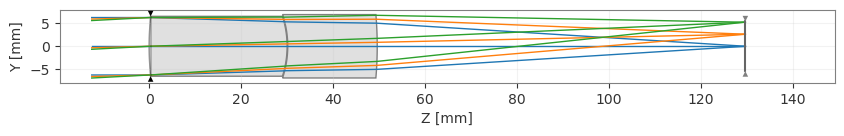

In [3]:
project=json.loads(r'''{
  "schemaVersion": 1,
  "name": "Two-Element Achromat 100 mm f8 · Fixed 588 nm Gaussian Plane",
  "objectAtInfinity": true,
  "fieldType": "angle",
  "fields": [
    0.0,
    1.5,
    3.0
  ],
  "primaryWavelength": 1,
  "aperture": 12.5,
  "wavelengths": [
    {
      "value": 486.0,
      "weight": 1.0
    },
    {
      "value": 588.0,
      "weight": 1.0
    },
    {
      "value": 656.0,
      "weight": 1.0
    }
  ],
  "analysis": {
    "mtfSamples": 64
  },
  "rayAiming": {
    "mode": "off"
  },
  "description": "New synthetic seed from thin-achromat power equations; fixed primary Gaussian plane.",
  "surfaces": [
    {
      "id": 0,
      "type": "object",
      "radius": null,
      "thickness": null,
      "material": "AIR",
      "semiDiameter": 6.25,
      "conic": 0.0,
      "asphere": [],
      "surfaceType": "STANDARD"
    },
    {
      "id": 1,
      "type": "stop",
      "surfaceType": "STANDARD",
      "radius": 68.77068305734099,
      "thickness": 29.99986031765753,
      "material": "SCHOTT:N-BK7",
      "semiDiameter": 6.512952154874549,
      "conic": 0.0,
      "asphere": []
    },
    {
      "id": 2,
      "type": "standard",
      "surfaceType": "STANDARD",
      "radius": -21.44498573821897,
      "thickness": 0.13500352248363634,
      "material": "AIR",
      "semiDiameter": 6.512952154874549,
      "conic": 0.0,
      "asphere": []
    },
    {
      "id": 3,
      "type": "standard",
      "surfaceType": "STANDARD",
      "radius": -21.772969771007816,
      "thickness": 19.464452243030678,
      "material": "SCHOTT:F2",
      "semiDiameter": 6.893814395853176,
      "conic": 0.0,
      "asphere": []
    },
    {
      "id": 4,
      "type": "standard",
      "surfaceType": "STANDARD",
      "radius": -81.3280382900337,
      "thickness": 80.07865326972832,
      "material": "AIR",
      "semiDiameter": 6.893814395853176,
      "conic": 0.0,
      "asphere": []
    },
    {
      "id": 5,
      "type": "image",
      "surfaceType": "STANDARD",
      "radius": null,
      "thickness": 0.0,
      "material": "AIR",
      "semiDiameter": 5.413270186827027,
      "conic": 0.0,
      "asphere": []
    }
  ],
  "fieldDefinitions": [
    {
      "x": 0.0,
      "y": 0.0,
      "weight": 1.0
    },
    {
      "x": 0.0,
      "y": 1.5,
      "weight": 1.0
    },
    {
      "x": 0.0,
      "y": 3.0,
      "weight": 1.0
    }
  ],
  "fieldWeights": [
    1.0,
    1.0,
    1.0
  ],
  "fieldUnit": "deg",
  "apertureType": "enpd",
  "apertureValue": 12.5,
  "apodization": {
    "type": "uniform",
    "factor": 0.0
  },
  "objectDistance": null,
  "designBounds": {
    "minimumCenterThicknessMm": 2.05,
    "maximumCenterThicknessMm": 30.0,
    "minimumVariableAirGapMm": 0.05,
    "maximumVariableAirGapMm": 20.0,
    "curvatureBound": "abs(c)<0.985/starting mechanical radius; spherical only",
    "scope": "Declared local search bounds. Published competition specifies CT minima, not a CT maximum."
  }
}''')
def build_lens(p):
    lens=Optic(name=p['name'])
    lens.surfaces.add(index=0,thickness=float('inf'))
    for i,s in enumerate(p['surfaces'][1:],1):
        material=IdealMaterial(1.) if s['material']=='AIR' else Material(
            s['material'].split(':')[1],catalog=s['material'].split(':')[0].lower(),match_policy=MatchPolicy.STRICT)
        lens.surfaces.add(index=i,radius=np.inf if s['radius'] is None else s['radius'],
            thickness=s['thickness'],material=material,is_stop=s['type']=='stop',
            conic=s['conic'],aperture=RadialAperture(s['semiDiameter']))
        lens.surfaces[-1].set_semi_aperture(s['semiDiameter'])
    lens.set_aperture(aperture_type='EPD',value=p['aperture'])
    lens.fields.set_type('angle')
    for f in p['fields']:lens.fields.add(y=f)
    for i,w in enumerate(p['wavelengths']):lens.wavelengths.add(
        value=w['value']/1000,weight=w['weight'],is_primary=i==p['primaryWavelength'])
    return lens

lens=build_lens(project)
display(pd.DataFrame(project['surfaces'])[['id','type','radius','thickness','material','semiDiameter']])
fig,ax=lens.draw(num_rays=3,show=False,figsize=(10,4))
plt.show()


## Fixed-plane Optiland evaluation

The score uses a 24×128 Gauss–Legendre unit-disk quadrature: 3,072 rays per field/color, 27,648 total. An additional 128-angle full rim is checked at every field and wavelength. Polychromatic color is not collapsed into a fake monochromatic RMS: the objective explicitly uses F-C lateral color at 3° plus 588 nm centroid RMS at 0°, 1.5°, 3°.

Numerical merit: `(chief_FC_um/5)^2 + 0.25*sum((RMS_588_um/20)^2) + P`. The 5 µm and 20 µm values are score scales, not hard limits. Published hard limits and additional local conventions are distinguished in the audit table. Equal auxiliary weights, the Gaussian plane, all-color distortion checks, positive full-radius air clearance, and separate-rim clearance are stated local conventions/guards.


In [4]:
def disk_quadrature(radial=24,azimuths=128):
    x,w=np.polynomial.legendre.leggauss(radial);r=np.sqrt((x+1)/2);a=2*np.pi*np.arange(azimuths)/azimuths
    return np.stack((r[:,None]*np.cos(a),r[:,None]*np.sin(a)),axis=-1).reshape(-1,2),np.repeat(w/(2*azimuths),azimuths)

rows=project['surfaces'][1:];vertices=np.r_[0.,np.cumsum([r['thickness'] for r in rows[:-1]])]
indices=np.array([[1.]+[float(np.asarray(s.material_post.n(w['value']/1000)).item()) for s in lens.surfaces.surfaces[1:]] for w in project['wavelengths']])
primary=1;stop=next(i for i,s in enumerate(project['surfaces']) if s['type']=='stop')
def transfer(wave,count):
    m=np.eye(2);z=0.;n=1.
    for i in range(count):
        s=rows[i];gap=vertices[i]-z;m=np.array([[1.,gap/n],[0.,1.]])@m
        after=indices[wave,i+1];c=0. if s['radius'] is None else 1/s['radius']
        m=np.array([[1.,0.],[-(after-n)*c,1.]])@m;z,n=vertices[i],after
    return m
m=transfer(primary,len(rows)-1);efl=-indices[primary,-1]/m[1,0]
gaussian_z=vertices[-2]-indices[primary,-1]*m[0,0]/m[1,0]
entrance=transfer(primary,stop);epz=entrance[0,1]/entrance[0,0]
def trace_field(field,wave,pupil):
    slope=np.array([0.,np.tan(np.deg2rad(field))]);direction=np.r_[slope,1.];direction/=np.linalg.norm(direction)
    xy=project['aperture']/2*pupil-epz*slope;origin=np.c_[xy-30*slope,np.full(len(pupil),-30.)]
    ray=RealRays(origin[:,0],origin[:,1],origin[:,2],np.full(len(pupil),direction[0]),np.full(len(pupil),direction[1]),np.full(len(pupil),direction[2]),np.ones(len(pupil)),np.full(len(pupil),project['wavelengths'][wave]['value']/1000))
    lens.surfaces.trace(ray,skip=1,record=False);point=np.c_[ray.x,ray.y,ray.z]
    valid=(np.asarray(ray.i)>0)&np.isfinite(point).all(axis=1)
    if not valid.all():raise RuntimeError('Incomplete pupil: rays cannot be discarded to improve the score.')
    return point,np.c_[ray.L,ray.M,ray.N]
def rms_um(point,q):
    offset=point[:,:2]-point[0,:2];offset-=q@offset
    return float(1000*np.sqrt(q@np.sum(offset*offset,axis=1)))
pupil,q=disk_quadrature();a=2*np.pi*np.arange(128)/128;rim=np.c_[np.cos(a),np.sin(a)]
points={};directions={};chief={};rms_rows=[];color_rows=[]
for fi,field in enumerate(project['fields']):
    for wave in range(3):
        points[fi,wave],directions[fi,wave]=trace_field(field,wave,pupil)
        chief[fi,wave]=trace_field(field,wave,np.zeros((1,2)))[0][0]
        trace_field(field,wave,rim)
    rms_rows.append({'fieldDeg':field,'rms588Um':rms_um(points[fi,1],q)})
    color_rows.append({'fieldDeg':field,'chiefFcUm':float(1000*(chief[fi,0][1]-chief[fi,2][1])),
        'centroidFcUm':float(1000*(q@points[fi,0][:,1]-q@points[fi,2][:,1]))})
chief_fc=color_rows[2]['chiefFcUm'];centroid_fc=color_rows[2]['centroidFcUm']
distortion=[{'wavelengthNm':w['value'],'percent':float(100*(chief[2,i][1]-efl*np.tan(np.deg2rad(3)))/(efl*np.tan(np.deg2rad(3))))} for i,w in enumerate(project['wavelengths'])]
axial=[]
for wi,w in enumerate(project['wavelengths']):
    t=transfer(wi,len(rows)-1);z=vertices[-2]-indices[wi,-1]*t[0,0]/t[1,0]
    axial.append({'wavelengthNm':w['value'],'GaussianImageZMm':float(z),'shiftFromFixed588PlaneMm':float(z-vertices[-1])})
print('Scored fixed image Z / mm:',vertices[-1]);print('588 nm Gaussian image Z / mm:',gaussian_z)
display(pd.DataFrame(rms_rows));display(pd.DataFrame(color_rows));display(pd.DataFrame(distortion));display(pd.DataFrame(axial))
print('UNSCORED F-C axial Gaussian separation / mm:',axial[0]['GaussianImageZMm']-axial[2]['GaussianImageZMm'])


Scored fixed image Z / mm: 129.67796935290016
588 nm Gaussian image Z / mm: 129.67796935290025


,fieldDeg,rms588Um
0,0.0,3.977651
1,1.5,2.063955
2,3.0,7.518690


,fieldDeg,chiefFcUm,centroidFcUm
0,0.0,0.000000,1.074378e-14
1,1.5,-0.012698,1.670513e-01
2,3.0,-0.026080,3.337274e-01


,wavelengthNm,percent
0,486.0,-0.049175
1,588.0,-0.058544
2,656.0,-0.048677


,wavelengthNm,GaussianImageZMm,shiftFromFixed588PlaneMm
0,486.0,130.058982,3.810128e-01
1,588.0,129.677969,8.526513e-14
2,656.0,129.594553,-8.341674e-02


UNSCORED F-C axial Gaussian separation / mm: 0.46442950106094827


In [5]:
def sag(row,r):
    c=0. if row['radius'] is None else 1/row['radius'];domain=1-c*c*r*r
    if domain<=0:raise ValueError('Invalid spherical mechanical domain.')
    return c*r*r/(1+np.sqrt(domain))
def element_bodies(p):
    result=[]
    for i,s in enumerate(p['surfaces'][1:-1],1):
        if s['material']=='AIR':continue
        if result and result[-1]['rear']==i and result[-1]['material']==s['material']:result[-1]['rear']=i+1
        else:result.append({'front':i,'rear':i+1,'material':s['material']})
    return result
def audit(p,efl_value):
    checks=[];s=p['surfaces'];z=np.r_[0.,np.cumsum([r['thickness'] for r in s[1:-1]])]
    def gate(name,value,low=None,high=None,scale=1.,condition=None,basis='published rule'):
        excess=float(not condition) if condition is not None else max(0.,low-value if low is not None else 0.,value-high if high is not None else 0.)
        checks.append({'constraint':name,'value':value,'min':low,'max':high,'basis':basis,'passed':excess<=1e-10,'P':(1e6 if condition is not None else 100)*(excess/scale)**2})
    bodies=element_bodies(p)
    gate('Infinite object',p['objectAtInfinity'],condition=p['objectAtInfinity']);gate('EFL / mm',efl_value,99.,101.)
    gate('F-number',efl_value/p['aperture'],7.84,8.16,.16);gate('EPD error / mm',abs(p['aperture']-12.5),high=1e-9,scale=.01)
    gate('Exactly two physical elements',len(bodies),condition=len(bodies)==2)
    gate('Spherical only',True,condition=all(not r.get('conic') and not any(r.get('asphere',[])) and r.get('surfaceType','STANDARD')=='STANDARD' for r in s))
    gate('Specified angular fields',p['fields'],condition=p['fields']==[0.,1.5,3.] and p['fieldType']=='angle' and all(r['x']==0 for r in p['fieldDefinitions']))
    gate('Exact spectrum / primary',True,condition=[w['value'] for w in p['wavelengths']]==[486.,588.,656.] and p['primaryWavelength']==1)
    gate('Equal auxiliary weights',True,condition=all(w['weight']==1 for w in p['wavelengths']) and all(f['weight']==1 for f in p['fieldDefinitions']),basis='local convention')
    gate('Fixed Gaussian588 plane error / mm',abs(vertices[-1]-gaussian_z),high=1e-7,scale=1e-5,basis='local plane definition')
    gate('Finite d-line RMS',True,condition=all(np.isfinite(r['rms588Um']) for r in rms_rows))
    gate('Complete grid plus128 rim',True,condition=True,basis='additional numerical integrity')
    elements=[];roles={'SCHOTT:N-BK7':'crown','SCHOTT:F2':'flint'}
    for body in bodies:
        a,b=body['front'],body['rear'];r=max(row['semiDiameter'] for row in s[a:b+1]);ct=float(z[b-1]-z[a-1]);et=ct+sag(s[b],r)-sag(s[a],r)
        n=indices[1,a];c1=0. if s[a]['radius'] is None else 1/s[a]['radius'];c2=0. if s[b]['radius'] is None else 1/s[b]['radius']
        power=(n-1)*(c1-c2)+(n-1)**2/n*ct*c1*c2;role=roles.get(body['material'])
        elements.append(dict(body,role=role,ctMm=ct,etMm=et,radiusMm=r,isolatedPowerInvMm=power))
        gate('CT '+str(a)+'-'+str(b)+' / mm',ct,2.,scale=2.);gate('ET '+str(a)+'-'+str(b)+' / mm',et,1.)
    crown=[e for e in elements if e['role']=='crown'];flint=[e for e in elements if e['role']=='flint']
    gate('Named catalog crown / flint',True,condition=len(crown)==1 and len(flint)==1)
    gate('Isolated crown power positive',True,condition=len(crown)==1 and crown[0]['isolatedPowerInvMm']>0)
    gate('Isolated flint power negative',True,condition=len(flint)==1 and flint[0]['isolatedPowerInvMm']<0)
    gate('BFD / mm',float(z[-1]-z[bodies[-1]['rear']-1]),60.,scale=60.)
    for prev,nxt in zip(elements,elements[1:]):
        if prev['rear']==nxt['front']:continue
        rear,front=prev['rear'],nxt['front'];r=min(prev['radiusMm'],nxt['radiusMm']);gap=z[front-1]-z[rear-1]
        minimum=float(min(gap,gap+sag(s[front],r)-sag(s[rear],r)))
        rim=float(gap+sag(s[front],nxt['radiusMm'])-sag(s[rear],prev['radiusMm']))
        gate('Full common-radius air gap / mm',minimum,1e-7,scale=.1,basis='additional nominal solid guard')
        gate('Separate rim axial clearance / mm',rim,0.,scale=.1,basis='additional nominal rim convention')
    for d in distortion:gate('Distortion % at3deg '+str(d['wavelengthNm'])+'nm',abs(d['percent']),high=.5,scale=.5,basis='published rule' if d['wavelengthNm']==588. else 'additional color check')
    return checks,elements
checks,elements=audit(project,efl)
P=sum(row['P'] for row in checks);rms_term=.25*sum((r['rms588Um']/20)**2 for r in rms_rows)
M=(chief_fc/5)**2+rms_term+P
display(pd.DataFrame(elements));display(pd.DataFrame(checks))
print(json.dumps({'allConstraintsPassed':all(r['passed'] for r in checks),'chiefFcUm':chief_fc,'centroidFcUm':centroid_fc,
    'colorTerm':(chief_fc/5)**2,'dRmsTerm':rms_term,'P':P,'LOCAL_M_NOT_OFFICIAL_SCORE':M,
    'alternative_centroid_based_merit_not_scored':(centroid_fc/5)**2+rms_term+P},indent=2))
assert all(r['passed'] for r in checks)
assert sum(r['P'] for r in audit(project,98.)[0])>0


,front,rear,material,role,ctMm,etMm,radiusMm,isolatedPowerInvMm
0,1,2,SCHOTT:N-BK7,crown,29.999860,28.677829,6.512952,0.028031
1,3,4,SCHOTT:F2,flint,19.464452,20.291931,6.893814,-0.018244


,constraint,value,min,max,basis,passed,P
0,Infinite object,True,NaN,NaN,published rule,True,0.0
1,EFL / mm,99.999999,9.900000e+01,1.010000e+02,published rule,True,0.0
2,F-number,8.0,7.840000e+00,8.160000e+00,published rule,True,0.0
3,EPD error / mm,0.0,NaN,1.000000e-09,published rule,True,0.0
4,Exactly two physical elements,2,NaN,NaN,published rule,True,0.0
5,Spherical only,True,NaN,NaN,published rule,True,0.0
6,Specified angular fields,"[0.0, 1.5, 3.0]",NaN,NaN,published rule,True,0.0
7,Exact spectrum / primary,True,NaN,NaN,published rule,True,0.0
8,Equal auxiliary weights,True,NaN,NaN,local convention,True,0.0
9,Fixed Gaussian588 plane error / mm,0.0,NaN,1.000000e-07,local plane definition,True,0.0


{
  "allConstraintsPassed": true,
  "chiefFcUm": -0.026079501624032275,
  "centroidFcUm": 0.3337273692149978,
  "colorTerm": 2.7205616198316084e-05,
  "dRmsTerm": 0.04788270191650157,
  "P": 0.0,
  "LOCAL_M_NOT_OFFICIAL_SCORE": 0.047909907532699886,
  "alternative_centroid_based_merit_not_scored": 0.052337660195028106
}


In [6]:
sensitivity=[]
for radial,arms in [(12,48),(16,96),(24,128),(32,192)]:
    sample,weight=disk_quadrature(radial,arms)
    values=[rms_um(trace_field(field,1,sample)[0],weight) for field in project['fields']]
    sensitivity.append({'radial':radial,'azimuths':arms,'rms588Um':values,
                        'localMerit':(chief_fc/5)**2+.25*sum((v/20)**2 for v in values)})
display(pd.DataFrame(sensitivity))
print('Max d-RMS sampling difference / um:',max(abs(a-b) for row in sensitivity for a,b in zip(row['rms588Um'],sensitivity[-1]['rms588Um'])))
# One alternative global real d-line focus is diagnostic only. It never
# separately focuses F or C, and does not replace the scored Gaussian plane.
covariance=variance=0.
for fi in range(3):
    xy=points[fi,1][:,:2];u=directions[fi,1][:,:2]/directions[fi,1][:,2,None]
    xy=xy-q@xy;u=u-q@u;covariance+=float(q@np.sum(xy*u,axis=1));variance+=float(q@np.sum(u*u,axis=1))
best_shift=-covariance/variance
print('UNSCORED single real d-line best-focus shift / mm:',best_shift)


,radial,azimuths,rms588Um,localMerit
0,12,48,"[3.9776508841247415, 2.0639550872967223, 7.518...",0.04791
1,16,96,"[3.9776508841251856, 2.0639550872970522, 7.518...",0.04791
2,24,128,"[3.977650884123283, 2.063955087296784, 7.51869...",0.04791
3,32,192,"[3.977650884124705, 2.063955087297077, 7.51869...",0.04791


Max d-RMS sampling difference / um: 1.4219736499399005e-12
UNSCORED single real d-line best-focus shift / mm: -0.012128158627705943


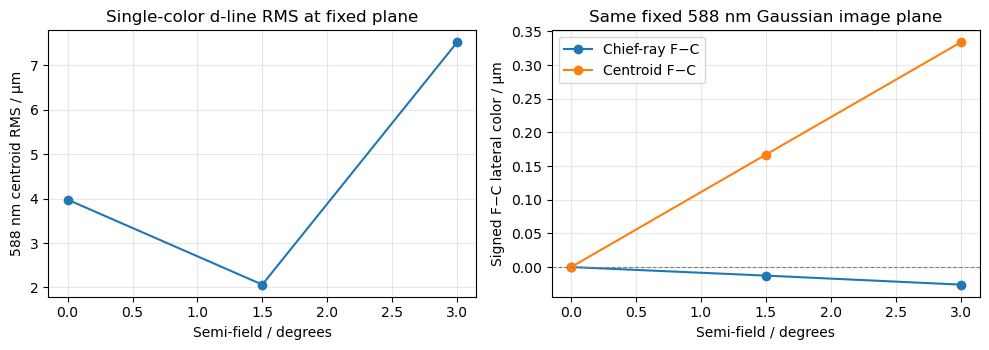

In [7]:
fig,axes=plt.subplots(1,2,figsize=(10,3.6))
axes[0].plot([r['fieldDeg'] for r in rms_rows],[r['rms588Um'] for r in rms_rows],'o-')
axes[0].set(xlabel='Semi-field / degrees',ylabel='588 nm centroid RMS / µm',title='Single-color d-line RMS at fixed plane')
for key,label in [('chiefFcUm','Chief-ray F−C'),('centroidFcUm','Centroid F−C')]:
    axes[1].plot([r['fieldDeg'] for r in color_rows],[r[key] for r in color_rows],'o-',label=label)
axes[1].axhline(0,color='gray',linestyle='--',linewidth=.8)
axes[1].set(xlabel='Semi-field / degrees',ylabel='Signed F−C lateral color / µm',title='Same fixed 588 nm Gaussian image plane')
axes[1].legend()
for ax in axes:ax.grid(True,alpha=.3)
fig.tight_layout();plt.show()


## Thickness tradeoff and independent cross-check

The CT≤30 mm nominal branch is selected for the stated local contest merit, not for practical manufacture. Its first CT is about **0.00014 mm below the search cap**, so this bound is active. The final CTs are **29.999860 / 19.464452 mm** and ODs **13.025904 / 13.787629 mm**. The separate CT≤14 mm comparison has CTs **14.000000 / 9.835959 mm**, merit **0.08794544**, chief F-C color about **−0.0488115 µm**, and 588 nm RMS **5.3980 / 2.6994 / 10.2046 µm**. The selected merit is approximately **0.04790991**. These are local bounded comparisons, not a global search or a published maximum-thickness requirement.

Independent checks retain physical-element merging across same-glass dummy planes, isolated thick-lens crown/flint power signs, full-radius spherical thickness/air clearance, 128-angle pupil rims at all three colors, and additional 0.75°/2.25° field probes. A separate auditor agreed with the final 32×192 result and passed nine deliberate positive/negative regression checks.

The unscored axial F-C separation of **0.4644295 mm** and the difference between chief and centroid lateral color are retained. Coatings, thermal effects, manufacturing tolerances, centering, procurement and assembly are outside this nominal entry. The records below are saved aggregate development checks, supplementary to the fresh Optiland outputs above.


In [8]:
verification_record=json.loads(r'''{
  "finalProjectRawSha256": "e9488fecf5eb9cff0c54ec1fc5a1daf1620b64d5cc3cb74d99acc8babe144bac",
  "definitions": {
    "localMetric": "(chief-ray F-C lateral color at3deg /5um)^2 +.25*sum((centroid d-line RMS atfield/20um)^2)+P",
    "plane": "One fixed primary588nm Gaussian image plane, geometry-eliminated before evaluation. F/C never independently refocused.",
    "roles": "Named conventional SCHOTT N-BK7 crown and F2 flint, withcatalog nd/Vd and isolated thick-element power signs. No new Abbe cutoff is presented as an official rule.",
    "penalty": "100*(normalized numerical excess)^2 per violation;1e6 per structural failure. All listed rules checked separately.",
    "mechanicalRadius": "Declared circular radii from full-pupil envelope plus0.15mm allocation; cemented members shareone radius. Nominal geometry only."
  },
  "elements": [
    {
      "front": 1,
      "rear": 2,
      "material": "SCHOTT:N-BK7",
      "role": "crown",
      "catalogNd": 1.5168,
      "catalogVd": 64.17,
      "isolatedPowerAt588InvMm": 0.028030951228535897,
      "centerThicknessMm": 29.99986031765753,
      "edgeThicknessMm": 28.677829099906173,
      "mechanicalRadiusMm": 6.512952154874549
    },
    {
      "front": 3,
      "rear": 4,
      "material": "SCHOTT:F2",
      "role": "flint",
      "catalogNd": 1.62004,
      "catalogVd": 36.37,
      "isolatedPowerAt588InvMm": -0.018244018329143775,
      "centerThicknessMm": 19.464452243030678,
      "edgeThicknessMm": 20.291931177672637,
      "mechanicalRadiusMm": 6.893814395853176
    }
  ],
  "imagePlane": {
    "fixedZMm": 129.67796935290016,
    "gaussianDLineZMm": 129.6779693529002,
    "bestRealDLineShiftMm": -0.012128158627766398,
    "alternativeSinglePlaneRmsDLine": [
      {
        "fieldDeg": 0.0,
        "rmsDLineUm": 4.493030491178951
      },
      {
        "fieldDeg": 1.5,
        "rmsDLineUm": 2.41651528989532
      },
      {
        "fieldDeg": 3.0,
        "rmsDLineUm": 7.051345577299901
      }
    ],
    "alternativeSinglePlaneChiefFcUm": -0.027277242391932077
  },
  "axialColorDiagnostic": {
    "rows": [
      {
        "wavelengthNm": 486.0,
        "gaussianImageZMm": 130.05898211478336,
        "shiftFromFixedDLinePlaneMm": 0.38101276188319844
      },
      {
        "wavelengthNm": 588.0,
        "gaussianImageZMm": 129.6779693529002,
        "shiftFromFixedDLinePlaneMm": 2.842170943040401e-14
      },
      {
        "wavelengthNm": 656.0,
        "gaussianImageZMm": 129.59455261372236,
        "shiftFromFixedDLinePlaneMm": -0.08341673917780668
      }
    ],
    "fcGaussianSeparationMm": 0.4644295010610051,
    "scored": false
  },
  "optiland": {
    "allValid": true,
    "maxInterceptDifferenceMm": 3.6415315207705135e-14,
    "chiefFcLateralColorUm": -0.026079501624032275,
    "maxRmsDLineDifferenceUm": 3.022027073029676e-12,
    "localMerit": 0.047909907532700906
  },
  "cuda": {
    "groups": 9,
    "rays": 27648,
    "allValidMasksMatch": true,
    "maxInterceptDifferenceMm": 0.0,
    "maxDirectionDifference": 0.0
  },
  "selection": {
    "sourceMethod": "Unchanged standalone-optics deterministic curvature candidates; WFE-ranked CPU/CUDA coarse screening and CPU20x64 dense replay",
    "sourceCandidateCount": 15,
    "sourceEligibleCount": 15,
    "sourceCurvatureSurfaces": [
      1,
      3,
      4
    ],
    "sourceDeltaCurvatureBoundsInvMm": [
      -5e-07,
      5e-07
    ],
    "sourceWinner": "candidate_00002",
    "sourcePlane": "All coarse candidates use the fixed starting d-line plane; selected geometry gets its new Gaussian588nm plane before refinement.",
    "refinementMethod": "SciPy bounded least_squares with standalone real-ray d-line RMS/chief-FC residuals; no global-optimality claim",
    "beforeLocalMerit": 0.04847046940900188,
    "refinedLocalMerit": 0.04790990753269858,
    "refinedEligible": true,
    "refinementAccepted": true,
    "refinementLog": {
      "seed": 0,
      "configuration": "air-spaced",
      "trainingMerit": 0.0479099077958199,
      "evaluations": 694,
      "elapsedSeconds": 1.1812064000041573,
      "optimizerStatus": 0
    }
  },
  "independentAudit": {
    "officialScore": false,
    "normalizedProjectSha256": "190ee8eece25afff6dea0d47718a5e405d2d218a8d127f25714294f0741dc246",
    "constraints": [
      {
        "name": "object_at_infinity",
        "passed": true,
        "value": true,
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": null
      },
      {
        "name": "spherical_surfaces_only",
        "passed": true,
        "value": null,
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": "Planes are spherical surfaces of infinite radius."
      },
      {
        "name": "specified_fields",
        "passed": true,
        "value": [
          0.0,
          1.5,
          3.0
        ],
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": null
      },
      {
        "name": "specified_wavelengths",
        "passed": true,
        "value": [
          486.0,
          588.0,
          656.0
        ],
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": null
      },
      {
        "name": "entrance_pupil_diameter_12p5_mm",
        "passed": true,
        "value": 12.5,
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": null
      },
      {
        "name": "declared_launch",
        "passed": true,
        "value": null,
        "penalty": 0.0,
        "scope": "local_definition",
        "detail": "Fixed physical angles and uniform incident pupil, with no per-colour field conversion."
      },
      {
        "name": "effective_focal_length_mm",
        "passed": true,
        "value": 99.99999918839563,
        "minimum": 99.0,
        "maximum": 101.0,
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": null
      },
      {
        "name": "f_number",
        "passed": true,
        "value": 7.999999935071651,
        "minimum": 7.84,
        "maximum": 8.16,
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": null
      },
      {
        "name": "fixed_588_nm_gaussian_image_plane",
        "passed": true,
        "value": -2.842170943040401e-14,
        "penalty": 0.0,
        "scope": "local_definition",
        "detail": "One common d-line Gaussian plane; F and C are never refocused independently."
      },
      {
        "name": "element_count",
        "passed": true,
        "value": 2.0,
        "minimum": 2,
        "maximum": 2,
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": null
      },
      {
        "name": "cemented_or_air_spaced_doublet",
        "passed": true,
        "value": null,
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": "Shared glass transition is cemented; separate ordered glass boundaries are air-spaced."
      },
      {
        "name": "element_1_catalog_material",
        "passed": true,
        "value": "SCHOTT:N-BK7",
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": null
      },
      {
        "name": "element_1_center_thickness_mm",
        "passed": true,
        "value": 29.99986031765753,
        "minimum": 2.0,
        "maximum": null,
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": null
      },
      {
        "name": "element_1_edge_thickness_mm",
        "passed": true,
        "value": 28.677829099906173,
        "minimum": 1.0,
        "maximum": null,
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": null
      },
      {
        "name": "element_1_full_radius_thickness_mm",
        "passed": true,
        "value": 28.677829099906173,
        "minimum": 1.0,
        "maximum": null,
        "penalty": 0.0,
        "scope": "nominal_geometry",
        "detail": null
      },
      {
        "name": "element_2_catalog_material",
        "passed": true,
        "value": "SCHOTT:F2",
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": null
      },
      {
        "name": "element_2_center_thickness_mm",
        "passed": true,
        "value": 19.464452243030678,
        "minimum": 2.0,
        "maximum": null,
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": null
      },
      {
        "name": "element_2_edge_thickness_mm",
        "passed": true,
        "value": 20.291931177672637,
        "minimum": 1.0,
        "maximum": null,
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": null
      },
      {
        "name": "element_2_full_radius_thickness_mm",
        "passed": true,
        "value": 19.464452243030678,
        "minimum": 1.0,
        "maximum": null,
        "penalty": 0.0,
        "scope": "nominal_geometry",
        "detail": null
      },
      {
        "name": "positive_crown_and_negative_flint",
        "passed": true,
        "value": [
          {
            "material": "SCHOTT:N-BK7",
            "role": "crown",
            "isolatedAirPowerPerMm": 0.028030951228535897
          },
          {
            "material": "SCHOTT:F2",
            "role": "flint",
            "isolatedAirPowerPerMm": -0.01824401832914378
          }
        ],
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": "Roles use explicit named catalog classifications, not an invented official Abbe cutoff. Each element is isolated in air for the power-sign check."
      },
      {
        "name": "back_focal_distance_mm",
        "passed": true,
        "value": 80.07865326972832,
        "minimum": 60.0,
        "maximum": null,
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": null
      },
      {
        "name": "full_radius_air_clearance_mm",
        "passed": true,
        "value": 0.13500352248363612,
        "minimum": 0.0,
        "maximum": null,
        "penalty": 0.0,
        "scope": "nominal_geometry",
        "detail": {
          "centerMm": 0.13500352248363612,
          "edgeMm": 0.15100046691800728,
          "minimumMm": 0.13500352248363612,
          "radiusMm": 6.512952154874549,
          "extrema": "exact endpoints for common spherical branches"
        }
      },
      {
        "name": "complete_sampled_pupil_transmission",
        "passed": true,
        "value": null,
        "penalty": 0.0,
        "scope": "nominal_geometry",
        "detail": {
          "failedQuadratureAndChiefRays": 0,
          "failedRimRays": 0,
          "scope": "All 3 fields x 3 wavelengths, plus 128 rays on the exact normalized pupil rim. Failed rays cannot improve the score."
        }
      },
      {
        "name": "finite_d_line_rms",
        "passed": true,
        "value": [
          {
            "fieldDeg": 0.0,
            "rmsUm": 3.9776508841215894
          },
          {
            "fieldDeg": 1.5,
            "rmsUm": 2.063955087295299
          },
          {
            "fieldDeg": 3.0,
            "rmsUm": 7.5186904383735795
          }
        ],
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": null
      },
      {
        "name": "distortion_percent_at_3_deg",
        "passed": true,
        "value": 0.05854428853315372,
        "minimum": null,
        "maximum": 0.5,
        "penalty": 0.0,
        "scope": "public_rule",
        "detail": null
      }
    ],
    "elements": [
      {
        "front": 1,
        "rear": 2,
        "material": "SCHOTT:N-BK7",
        "role": "crown",
        "index588": 1.5167817367777037,
        "abbeVd": 64.17,
        "isolatedAirPowerPerMm": 0.028030951228535897,
        "centerThicknessMm": 29.99986031765753,
        "mechanicalRadiusMm": 6.512952154874549,
        "thickness": {
          "centerMm": 29.99986031765753,
          "edgeMm": 28.677829099906173,
          "minimumMm": 28.677829099906173,
          "radiusMm": 6.512952154874549,
          "extrema": "exact endpoints for common spherical branches"
        }
      },
      {
        "front": 3,
        "rear": 4,
        "material": "SCHOTT:F2",
        "role": "flint",
        "index588": 1.6200022808636685,
        "abbeVd": 36.37,
        "isolatedAirPowerPerMm": -0.01824401832914378,
        "centerThicknessMm": 19.464452243030678,
        "mechanicalRadiusMm": 6.893814395853176,
        "thickness": {
          "centerMm": 19.464452243030678,
          "edgeMm": 20.291931177672637,
          "minimumMm": 19.464452243030678,
          "radiusMm": 6.893814395853176,
          "extrema": "exact endpoints for common spherical branches"
        }
      }
    ],
    "rmsD": [
      {
        "fieldDeg": 0.0,
        "rmsUm": 3.9776508841215894
      },
      {
        "fieldDeg": 1.5,
        "rmsUm": 2.063955087295299
      },
      {
        "fieldDeg": 3.0,
        "rmsUm": 7.5186904383735795
      }
    ],
    "declaredSearchBounds": {
      "minimumCenterThicknessMm": 2.05,
      "maximumCenterThicknessMm": 30.0,
      "minimumVariableAirGapMm": 0.05,
      "maximumVariableAirGapMm": 20.0,
      "curvatureBound": "abs(c)<0.985/starting mechanical radius; spherical only",
      "scope": "Declared local search bounds. Published competition specifies CT minima, not a CT maximum."
    },
    "eflDmm": 99.99999918839563,
    "dGaussianImageZMm": 129.6779693529002,
    "imagePlaneErrorMm": -2.842170943040401e-14,
    "sampling": {
      "radialOrder": 32,
      "azimuths": 192,
      "raysPerFieldWave": 6144,
      "rimRaysPerFieldWave": 128,
      "convergenceCertified": false
    },
    "definitions": {
      "lateralColor": "Absolute F--C chief-ray separation at 3 degrees on the fixed 588 nm Gaussian plane",
      "centroidColor": "Separate diagnostic: F--C quadrature centroid separation at that same plane",
      "distortion": "588 nm chief height / (EFL_588 * tan(3 degrees)) - 1",
      "merit": "(chief_LC_um/5)^2 + .25*sum_fields((RMS_588_um/20)^2) + explicit local P",
      "limitations": "Public rules do not define chief versus centroid LC, exact d focus, sampling or penalty scale. This is an explicit reproducible local interpretation, not official scoring."
    },
    "chiefLateralColorUm": 0.026079501623144097,
    "centroidLateralColorUm": 0.33372736915904255,
    "distortionPercent": -0.05854428853315372,
    "objective": 0.047909907532706277,
    "penalty": 0.0,
    "passed": true,
    "localMerit": 0.047909907532706277,
    "additionalUnscoredDiagnostics": {
      "scored": false,
      "allSampledRaysValid": true,
      "sampling": {
        "radialOrder": 24,
        "azimuths": 128,
        "rimAngles": 128,
        "fieldsDeg": [
          0.0,
          0.75,
          1.5,
          2.25,
          3.0
        ],
        "wavelengthsNm": [
          486.0,
          588.0,
          656.0
        ]
      },
      "intermediateFields": [
        {
          "fieldDeg": 0.75,
          "rmsDLineUm": 3.4023188954953394,
          "chiefFcUm": 0.006306259278554549,
          "distortionDPercent": -0.0036555042030050012,
          "allThreeWaveInteriorChiefAndRimValid": true
        },
        {
          "fieldDeg": 2.25,
          "rmsDLineUm": 3.1883477022070137,
          "chiefFcUm": 0.0192595163843734,
          "distortionDPercent": -0.032916400635809716,
          "allThreeWaveInteriorChiefAndRimValid": true
        }
      ],
      "gaussianChromaticFocus": {
        "rows": [
          {
            "wavelengthNm": 486.0,
            "relativeToDPlaneMm": 0.38101276188317
          },
          {
            "wavelengthNm": 588.0,
            "relativeToDPlaneMm": 0.0
          },
          {
            "wavelengthNm": 656.0,
            "relativeToDPlaneMm": -0.0834167391778351
          }
        ],
        "absoluteFcAxialSeparationMm": 0.4644295010610051,
        "definition": "First-order axial focus, a separate unscored diagnostic. Small lateral colour is not proof of broadband diffraction-limited achromatism."
      },
      "singleBestRealDPlane": {
        "shiftFromGaussianMm": -0.012128158627763357,
        "rmsDLine": [
          {
            "fieldDeg": 0.0,
            "rmsDLineUm": 4.493030491179274
          },
          {
            "fieldDeg": 1.5,
            "rmsDLineUm": 2.416515289895292
          },
          {
            "fieldDeg": 3.0,
            "rmsDLineUm": 7.051345577300037
          }
        ],
        "chiefFcUm": 0.0272772423910439,
        "definition": "One common plane minimizing the sum of d-line centroid variances over the three official fields; F and C remain on this same plane."
      }
    },
    "testedGridSensitivity": {
      "convergenceCertified": false,
      "definition": "Independent density sensitivity over the tested pupil grids; this does not certify every unsampled field, wavelength or perturbation.",
      "rows": [
        {
          "radialOrder": 16,
          "azimuths": 96,
          "passed": true,
          "localMerit": 0.047909907532707276,
          "maxRmsDifferenceToDensestUm": 9.681144774731365e-14,
          "objectiveDifferenceToDensest": 9.992007221626409e-16
        },
        {
          "radialOrder": 24,
          "azimuths": 128,
          "passed": true,
          "localMerit": 0.04790990753270201,
          "maxRmsDifferenceToDensestUm": 8.570921750106208e-13,
          "objectiveDifferenceToDensest": 4.2674197509029455e-15
        },
        {
          "radialOrder": 32,
          "azimuths": 192,
          "passed": true,
          "localMerit": 0.047909907532706277,
          "maxRmsDifferenceToDensestUm": 0.0,
          "objectiveDifferenceToDensest": 0.0
        }
      ]
    },
    "sourceFileSha256": "e9488fecf5eb9cff0c54ec1fc5a1daf1620b64d5cc3cb74d99acc8babe144bac"
  },
  "independentTests": {
    "createdUtc": "2026-11-10T12:13:22.171588+00:00",
    "passed": true,
    "testsRun": 9,
    "elapsedSeconds": 0.47081609999440843,
    "testIds": [
      "independent_audit.IndependentAuditTests.test_air_spaced_edge_overlap_cannot_hide_behind_positive_center_gap",
      "independent_audit.IndependentAuditTests.test_deliberate_epd_surface_field_and_role_violations_receive_penalties",
      "independent_audit.IndependentAuditTests.test_doublet_formula_does_not_invent_equal_weight_eligibility",
      "independent_audit.IndependentAuditTests.test_dummy_glass_stop_does_not_create_extra_element",
      "independent_audit.IndependentAuditTests.test_free_image_plane_motion_cannot_game_lateral_colour",
      "independent_audit.IndependentAuditTests.test_full_radius_separation_matches_dense_spherical_domain",
      "independent_audit.IndependentAuditTests.test_good_cemented_pair_passes_and_shared_seam_counts_two",
      "independent_audit.IndependentAuditTests.test_other_public_rule_violations_all_receive_positive_penalties",
      "independent_audit.IndependentAuditTests.test_pupil_rim_failure_is_not_hidden_by_valid_interior_quadrature"
    ],
    "auditImplementationSha256": "b346f29662d3b2d9d9026147fa00e185cef0f57ed4c56ae023700e3a3d2bcb40",
    "frozenProjectSha256": "e9488fecf5eb9cff0c54ec1fc5a1daf1620b64d5cc3cb74d99acc8babe144bac",
    "scope": "Local independent auditor regressions; the submission notebook is independently self-contained and does not require the local Optiwork checkout used by these developer tests.",
    "covered": "Object conjugate, field/spectrum declarations, EPD/EFL/f-number, two physical elements with cemented/dummy semantics, sphere/catalog/role and power signs, CT/ET/BFD/distortion/finite RMS, full-radius thickness and air overlap, exact pupil rim, and fixed d-plane cheating; no invented equal-weight rule.",
    "officialScore": false,
    "additionalFinalDiagnosticsExecuted": true
  },
  "conventionalCt14": {
    "localMerit": 0.08794544373654634,
    "chiefFcLateralColorUm": -0.04881148937840862,
    "centroidFcLateralColorUm": -0.3320470448739954,
    "rmsDLine": [
      {
        "fieldDeg": 0.0,
        "rmsDLineUm": 5.398031831231721
      },
      {
        "fieldDeg": 1.5,
        "rmsDLineUm": 2.699417150081557
      },
      {
        "fieldDeg": 3.0,
        "rmsDLineUm": 10.204637447828667
      }
    ],
    "elements": [
      {
        "front": 1,
        "rear": 2,
        "material": "SCHOTT:N-BK7",
        "role": "crown",
        "catalogNd": 1.5168,
        "catalogVd": 64.17,
        "isolatedPowerAt588InvMm": 0.027286687485244574,
        "centerThicknessMm": 13.999999999999996,
        "edgeThicknessMm": 12.829341126112087,
        "mechanicalRadiusMm": 6.43700535911386
      },
      {
        "front": 3,
        "rear": 4,
        "material": "SCHOTT:F2",
        "role": "flint",
        "catalogNd": 1.62004,
        "catalogVd": 36.37,
        "isolatedPowerAt588InvMm": -0.017587023251729138,
        "centerThicknessMm": 9.835959329429926,
        "edgeThicknessMm": 10.499575529748661,
        "mechanicalRadiusMm": 6.593307105273572
      }
    ]
  }
}''')
print(json.dumps(verification_record,indent=2))

{
  "finalProjectRawSha256": "e9488fecf5eb9cff0c54ec1fc5a1daf1620b64d5cc3cb74d99acc8babe144bac",
  "definitions": {
    "localMetric": "(chief-ray F-C lateral color at3deg /5um)^2 +.25*sum((centroid d-line RMS atfield/20um)^2)+P",
    "plane": "One fixed primary588nm Gaussian image plane, geometry-eliminated before evaluation. F/C never independently refocused.",
    "roles": "Named conventional SCHOTT N-BK7 crown and F2 flint, withcatalog nd/Vd and isolated thick-element power signs. No new Abbe cutoff is presented as an official rule.",
    "penalty": "100*(normalized numerical excess)^2 per violation;1e6 per structural failure. All listed rules checked separately.",
    "mechanicalRadius": "Declared circular radii from full-pupil envelope plus0.15mm allocation; cemented members shareone radius. Nominal geometry only."
  },
  "elements": [
    {
      "front": 1,
      "rear": 2,
      "material": "SCHOTT:N-BK7",
      "role": "crown",
      "catalogNd": 1.5168,
      "catalogVd": 64

## Sources and license notice

Optiland is pinned to public commit `a9e544a2e058f1c1b64606e9ce90e6dc103efee1`; original standalone-optics source is pinned to `d130999165abc8ccc1865c4ef145cd6bda191a4d` with file hashes above. The final prescription is self-created from ordinary thin-achromat power equations; no gallery/private prescription was copied for this case.

Optiland upstream notice:

```text
MIT License

Copyright (c) 2024 Kramer Harrison

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.

```